# Part 2 · Explore Ames house sales

How closely does above-ground living area track sale price, and what should we check before training? We reserve the latest year first. All price summaries, quality checks and charts below use earlier sales.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sales = pd.read_csv(root / "data" / "ames.csv")

# Use the same year boundary in later notebooks.
assert sales["Yr.Sold"].between(2006, 2010).all()
train = sales.loc[sales["Yr.Sold"] < 2010].copy()
test = sales.loc[sales["Yr.Sold"] == 2010].copy()
assert len(train) + len(test) == len(sales) and len(train) and len(test)
print(f"Training (2006–2009): {len(train):,} sales")
print(f"Reserved test (2010): {len(test):,} sales")

Training (2006–2009): 2,589 sales
Reserved test (2010): 341 sales


The split follows the intended use: learn from older sales and estimate a later sale. We use only the size of the reserved set here. During model selection, validation will take place within the training period.

In [2]:
features = ["area", "Neighborhood", "Year.Built"]
target = "price"
print("Missing values in the starting features and target:")
print(train[features + [target]].isna().sum().to_string())
print("Repeated training rows:", train.duplicated().sum())
print("Repeated parcel IDs in training:", train["PID"].duplicated().sum())
print("Nonpositive prices or living areas:", ((train[target] <= 0) | (train["area"] <= 0)).sum())

print("\nOther columns with the most missing entries:")
print(train.isna().sum().nlargest(5).to_string())

Missing values in the starting features and target:
area            0
Neighborhood    0
Year.Built      0
price           0
Repeated training rows: 0
Repeated parcel IDs in training: 0
Nonpositive prices or living areas: 0

Other columns with the most missing entries:
Pool.QC         2576
Misc.Feature    2505
Alley           2411
Fence           2094
Mas.Vnr.Type    1555


The starting fields are complete in the training sample. Other fields need interpretation. For example, a blank pool-quality entry may reflect the absence of a pool. Before using that field, check its definition and compare it with pool area. Dropping every row containing a blank would discard many usable sales.

In [3]:
prices = train[target]
print(prices.describe().round().to_string())
area_price_corr = train["area"].corr(prices)
print(f"\nPearson correlation, area and price: {area_price_corr:.3f}")

count      2589.0
mean     181876.0
std       80505.0
min       13100.0
25%      129900.0
50%      161500.0
75%      214000.0
max      755000.0

Pearson correlation, area and price: 0.709


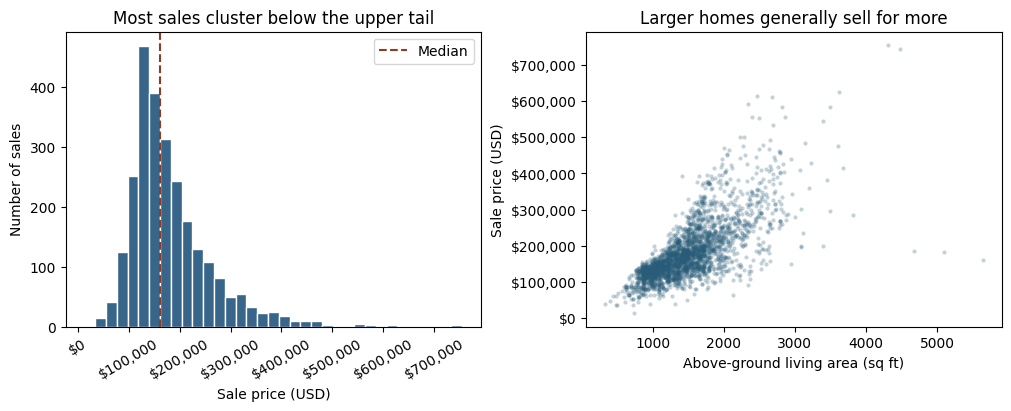

In [4]:
from matplotlib.ticker import StrMethodFormatter

fig, (hist, scatter) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
hist.hist(prices, bins=35, color="#38658a", edgecolor="white")
hist.axvline(prices.median(), color="#933b21", linestyle="--", label="Median")
hist.legend()
hist.set(title="Most sales cluster below the upper tail", xlabel="Sale price (USD)", ylabel="Number of sales")
hist.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
hist.tick_params(axis="x", labelrotation=30)

scatter.scatter(train["area"], prices, s=9, alpha=0.28, color="#285c78", linewidths=0)
scatter.set(title="Larger homes generally sell for more", xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD)")
scatter.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.show()

## What the training data tells us

- The median sale was **$161,500**. The mean was around **$181,876**. The histogram shows a small number of expensive sales extending the upper tail.
- Area and price have a Pearson correlation of **0.709**. Homes of similar size still sold for different amounts. This relationship alone cannot tell us what an addition would do to a specific home's price.
- A few homes beyond 4,000 square feet sold well below other large homes. We will keep these observations while we investigate their sale conditions. An unusual point can still represent a genuine sale.

**Checkpoint:** Why would choosing features after looking at 2010 sale prices make the final evaluation less trustworthy?